Instructions: before running, add your email address in Section 2 (Parameters) for access to the PubMed API

### 📦 1 | Install & Import Required Packages
---

**1.1 | Install Required Packages**

In [ ]:
!pip install biopython >/dev/null
!pip install plotnine >/dev/null

**1.2 | Import Required Packages**

In [ ]:
from    Bio import Entrez
import  pandas as pd
from    datetime import datetime
import  matplotlib.pyplot as plt
from    plotnine import *
from    mizani.formatters import comma_format
import  time

### 🔧 2 | Parameters
---

In [ ]:
# Set your email before using Entrez
Entrez.email = "your.email@example.org"  # Replace with a contact email before running

# Create list of diseases for plotting | ['Long COVID', 'ME/CFS', 'Fibromyalgia', 'POTS', 'MCAS', 'Chronic Lyme', 'Dysautonomia', 'PANS/PANDAS', 'HIV/AIDS', 'Multiple Sclerosis', 'Parkinson\'s Disease', 'Rheumatoid Arthritis']
disease_list = ['Long COVID', 'ME/CFS', 'Fibromyalgia', 'POTS', 'MCAS', 'Chronic Lyme', 'Dysautonomia', 'PANS/PANDAS']

# Define the start and end years for the PubMed API search
start_year = 1980
end_year = 2025

# Define single year for across-disease comparison
single_year = 2025

# Define disease colours
disease_colors = {
    "ME/CFS": "#7BB3F3",
    "Long COVID": "#E57399",
    "Fibromyalgia": "#FFD8A8",
    "POTS": "#B6FDFF",
    "MCAS": "#FFC2E6",
    "Chronic Lyme": "#B4D9B5",
    "Dysautonomia": "#D7B3FF",
    "PANS/PANDAS": "#F6C8A4",
    "HIV/AIDS": "#F2A9A1",
    "Multiple Sclerosis": "#D3D3D3",
    "Parkinson's Disease": "#D7B3FF",
    "Rheumatoid Arthritis": "#B4D9B5"
}

# Dictionary of search terms for PubMed API search
search_terms = {
    "ME/CFS": (
        '("ME/CFS" '
        'OR "CFS/ME" '
        'OR "Myalgic Encephalomyelitis" '
        'OR "Chronic Fatigue Syndrome" '
        'OR "Systemic Exertion Intolerance Disease")'
    ),
    "Long COVID": (
        '("Long COVID" '
        'OR "Post-COVID Syndrome" '
        'OR "Long-Haul COVID" '
        'OR "Post-acute sequelae of COVID-19" '
        'OR "Post-COVID-19 condition")'
    ),
    "Fibromyalgia": (
        '("Fibromyalgia" '
        'OR "Fibromyalgia Syndrome")'
    ),
    "POTS": (
        '("Postural Tachycardia Syndrome" '
        'OR "PoTS" '
        'OR "POTS" '
        'OR "Postural Orthostatic Tachycardia Syndrome")'
    ),
    "MCAS": (
        '("Mast Cell Activation Syndrome" '
        'OR "MCAS" '
        'OR "mast cell activation disorder" '
        'OR "MCAD")'
    ),
    "Dysautonomia": (
        '("Dysautonomia")'
    ),
    "Chronic Lyme": (
        '("Chronic Lyme" '
        'OR "Chronic Lyme Disease" '
        'OR "Chronic Lyme Borreliosis" '
        'OR "Chronic Borreliosis" '
        'OR "Persistent Lyme Infection" '
        'OR "Persistent Borrelia Infection" '
        'OR "Post-Lyme Disease Syndrome" '
        'OR "PLDS" '
        'OR "Post-Treatment Lyme Disease Syndrome" '
        'OR "PTLDS" '
        'OR "Late-Stage Lyme Disease" '
        'OR "Late Disseminated Lyme Disease" '
        'OR "Neuroborreliosis")'
    ),
    "PANS/PANDAS": (
        '("PANS" '
        'OR "Pediatric Acute-onset Neuropsychiatric Syndrome" '
        'OR "PANDAS" '
        'OR "Pediatric Autoimmune Neuropsychiatric Disorders Associated with Streptococcus")'
    ),
    "Multiple Sclerosis": (
        '("Multiple Sclerosis")'
    ),
    "HIV/AIDS": (
        '("HIV" '
        'OR "AIDS" '
        'OR "HIV/AIDS" '
        'OR "Human Immunodeficiency Virus")'
    ),
    "Parkinson's Disease": (
        '("Parkinson\'s Disease"[MeSH Terms] '
        'OR "Parkinson\'s Disease" '
        'OR "Parkinson Disease" '
        'OR "Idiopathic Parkinson\'s Disease")'
    ),
    "Rheumatoid Arthritis": (
        '("Rheumatoid Arthritis"[MeSH Terms] '
        'OR "Rheumatoid Arthritis" '
        'OR "Chronic Polyarthritis")'
    )
}

### 🚰  3 | Data Import - from PubMed API
---

In [ ]:
def fetch_pubmed_data_for_multiple_terms(search_terms, start_year, end_year):
    """
    Fetches publication counts from PubMed for multiple search terms over a range of years.

    :param search_terms: Dictionary of search terms (diseases) and their PubMed query strings.
                        IMPORTANT: Multi-word phrases should be surrounded by quotes
                        if you want them treated as an exact phrase.
    :param start_year: Start year for the data collection.
    :param end_year: End year for the data collection.
    :return: DataFrame with years as rows and diseases as columns, containing publication counts.
    """

    publication_counts = {term: [] for term in search_terms}
    years = range(start_year, end_year + 1)

    for year in years:
        for disease_label, query in search_terms.items():
            # Construct the query with [dp] (date of publication)
            full_query = f"{query} AND ({year}[dp])"

            handle = Entrez.esearch(db="pubmed", term=full_query, retmax=100000)
            record = Entrez.read(handle)
            count = int(record["Count"])
            publication_counts[disease_label].append(count)
            handle.close()

            # Optional: small sleep to respect NCBI rate limits (~3 requests/sec)
            time.sleep(0.34)

    # Create a DataFrame from the collected data
    df = pd.DataFrame(publication_counts, index=years)
    df.index.name = 'Year'
    return df

# Fetching the data (to be executed in an environment where Biopython is installed)
publications_df = fetch_pubmed_data_for_multiple_terms(search_terms, start_year, end_year)

# Check result
publications_df.tail()

,ME/CFS,Long COVID,Fibromyalgia,POTS,MCAS,Dysautonomia,Chronic Lyme,PANS/PANDAS,Multiple Sclerosis,HIV/AIDS,Parkinson's Disease,Rheumatoid Arthritis
Year,,,,,,,,,,,,
2021,425,828,891,471,175,304,226,196,6886,23566,10015,6363
2022,375,2136,895,454,153,259,219,178,6736,23126,9862,6180
2023,416,2657,964,463,173,281,196,195,6035,21692,9624,5976
2024,381,2752,976,444,139,299,203,249,6325,22327,10265,6054
2025,438,2496,1033,499,181,327,217,263,6629,23550,11644,6613


In [ ]:
# Transforming the DataFrame to long format
df_long = publications_df.reset_index().melt(id_vars='Year', var_name='Disease', value_name='Publications')

# Calculating cumulative publications for each disease
df_long['Cumulative Publications'] = df_long.groupby('Disease')['Publications'].cumsum()

# Check result
df_long

,Year,Disease,Publications,Cumulative Publications
0,1980,ME/CFS,5,5
1,1981,ME/CFS,5,10
2,1982,ME/CFS,1,11
3,1983,ME/CFS,2,13
4,1984,ME/CFS,6,19
...,...,...,...,...
547,2021,Rheumatoid Arthritis,6363,113693
548,2022,Rheumatoid Arthritis,6180,119873
549,2023,Rheumatoid Arthritis,5976,125849
550,2024,Rheumatoid Arthritis,6054,131903


### 🥋 4 | Data Wrangling
---

In [ ]:
# Filter dataframe for required diseases
df_plot_disease = df_long[df_long['Disease'].isin(disease_list)]

# Check result
df_plot_disease

,Year,Disease,Publications,Cumulative Publications
0,1980,ME/CFS,5,5
1,1981,ME/CFS,5,10
2,1982,ME/CFS,1,11
3,1983,ME/CFS,2,13
4,1984,ME/CFS,6,19
...,...,...,...,...
363,2021,PANS/PANDAS,196,1830
364,2022,PANS/PANDAS,178,2008
365,2023,PANS/PANDAS,195,2203
366,2024,PANS/PANDAS,249,2452


In [ ]:
# Filter for specific year selected
df_plot_disease_year = df_plot_disease[df_plot_disease['Year']==single_year]

# Sort values on Publications
df_plot_disease_year = df_plot_disease_year.sort_values('Publications', ascending=False)

# Changing 'Disease' to a categorical type with ordered categories
df_plot_disease_year['Disease'] = pd.Categorical(df_plot_disease_year['Disease'], categories=df_plot_disease_year['Disease'].unique())

# Check result
df_plot_disease_year

,Year,Disease,Publications,Cumulative Publications
91,2025,Long COVID,2496,10927
137,2025,Fibromyalgia,1033,17538
183,2025,POTS,499,7122
45,2025,ME/CFS,438,8565
275,2025,Dysautonomia,327,4125
367,2025,PANS/PANDAS,263,2715
321,2025,Chronic Lyme,217,4831
229,2025,MCAS,181,2831


### 📈  5 | Visualise Results
---

/usr/local/lib/python3.12/dist-packages/plotnine/geoms/geom_path.py:100: PlotnineWarning: geom_path: Removed 1 rows containing missing values.


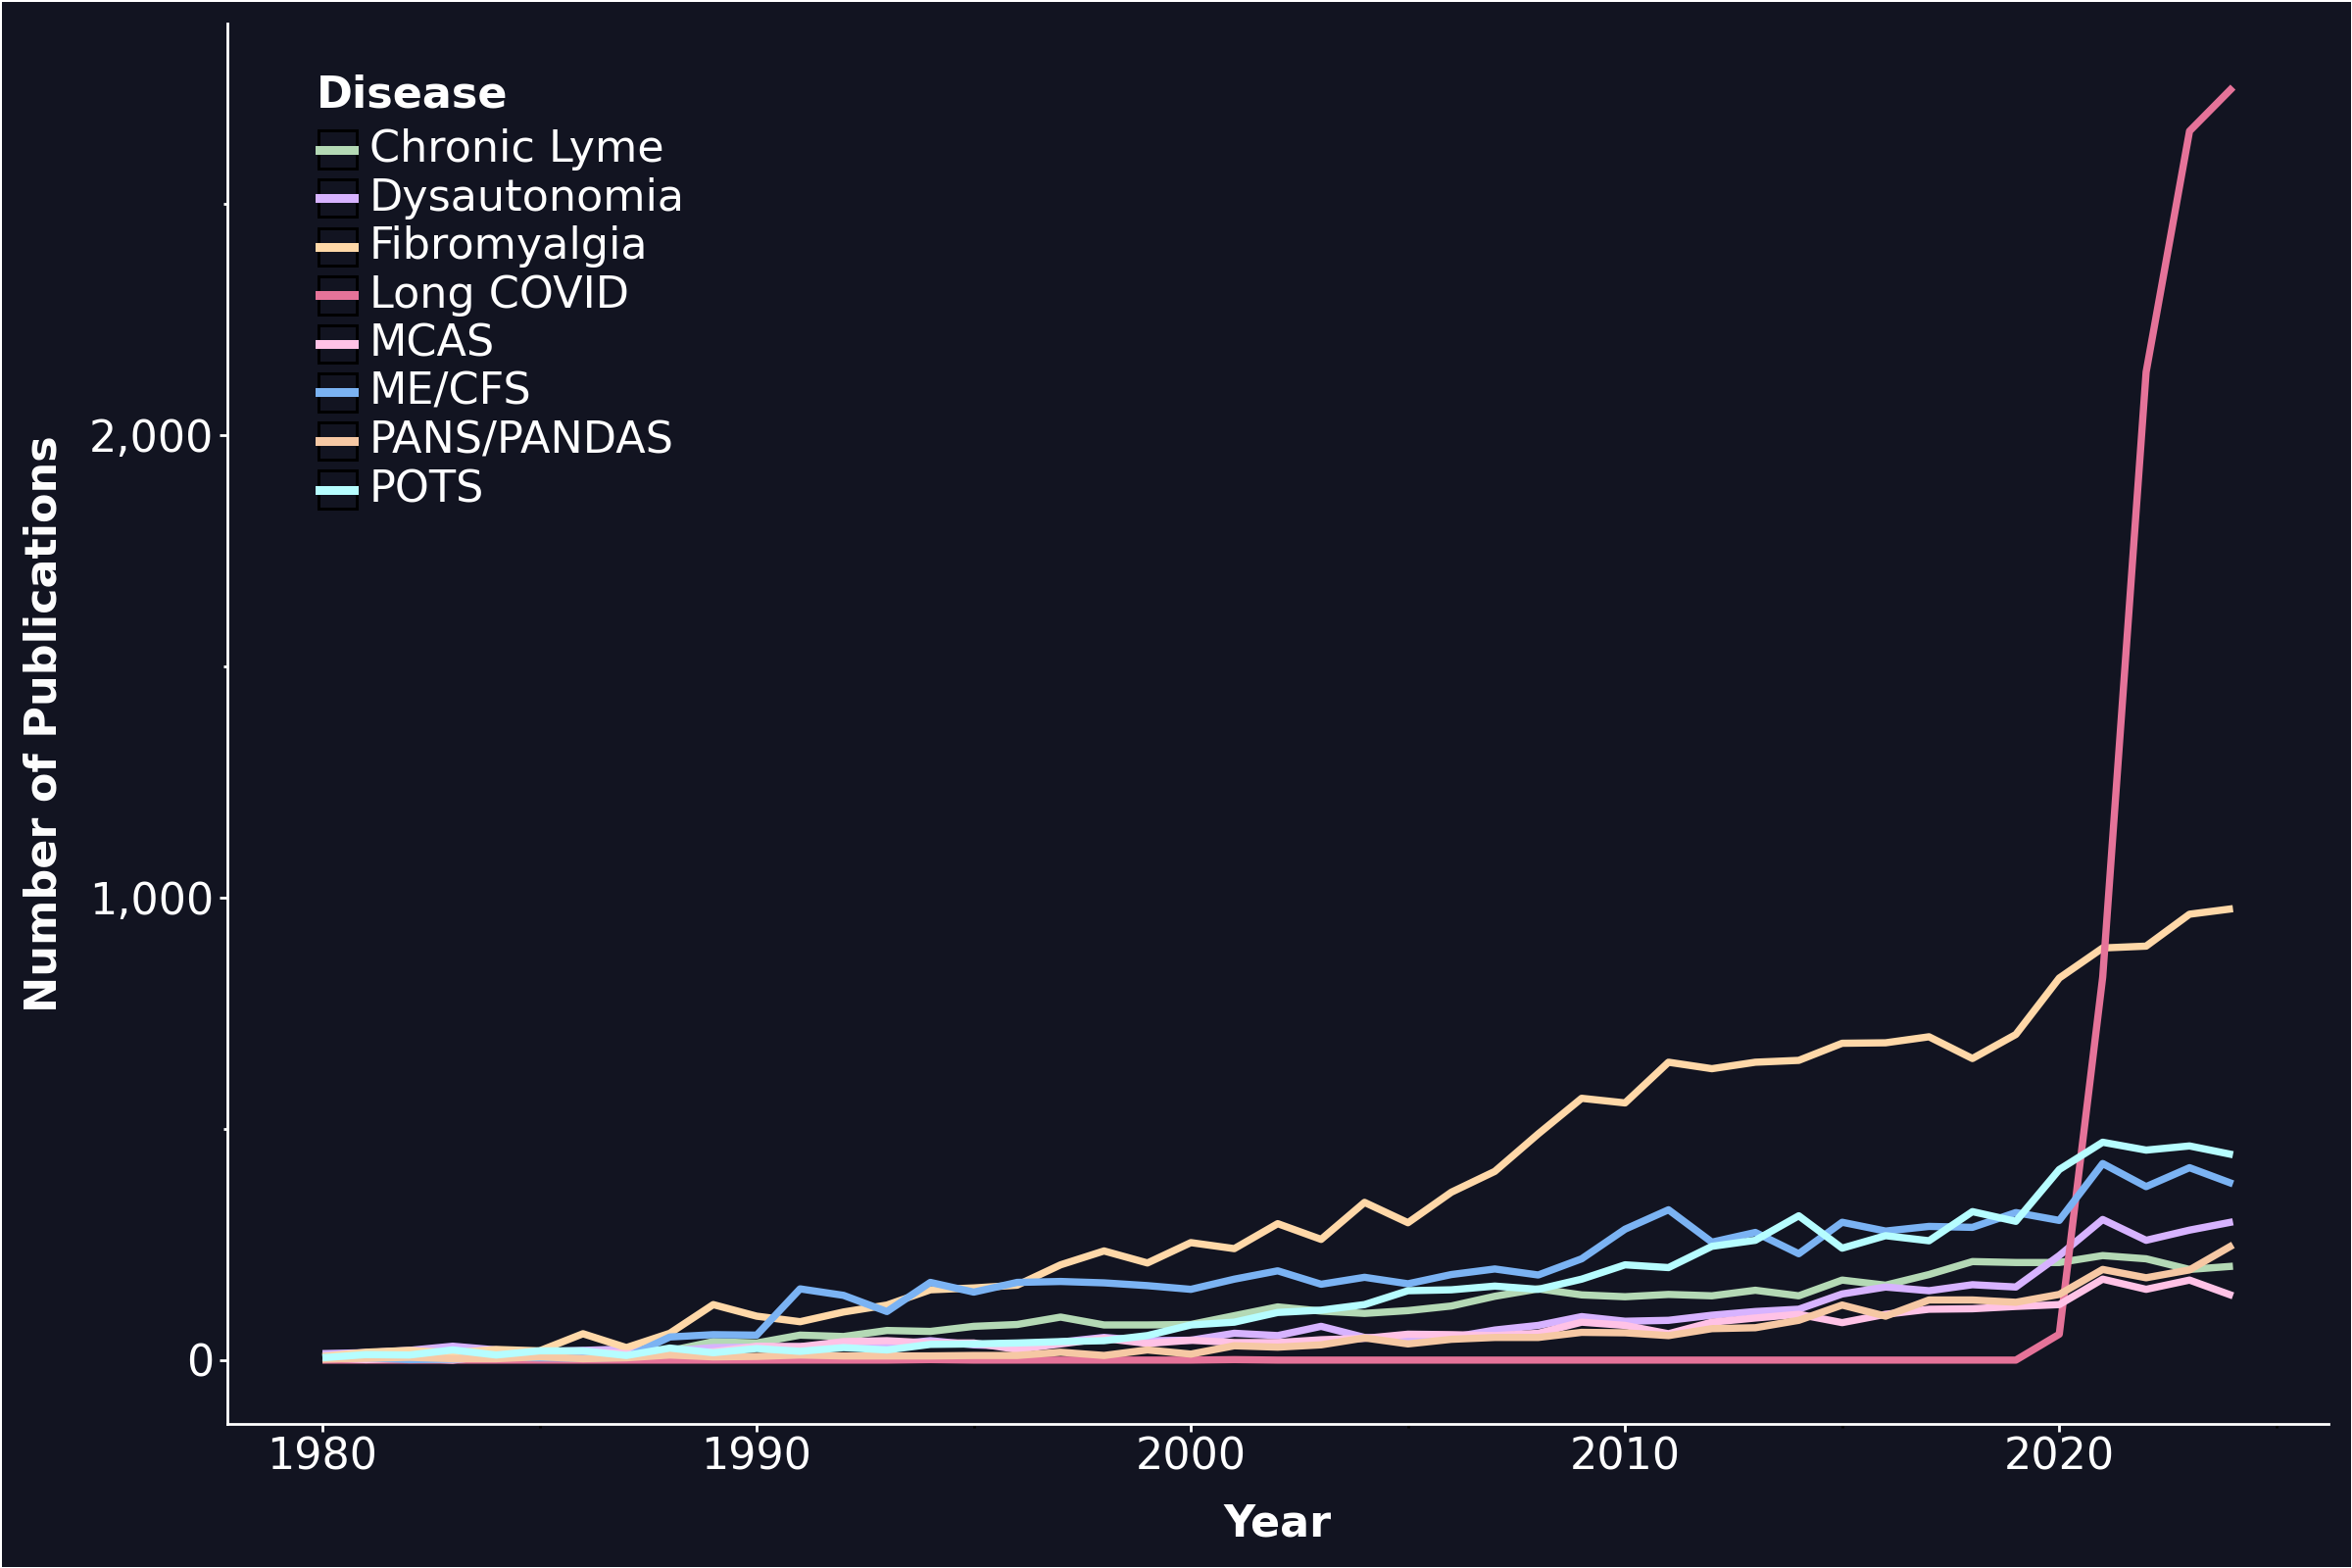

In [ ]:
# Update the plot with pastel colors
plot = (ggplot(df_plot_disease, aes(x='Year', y='Publications', color='Disease')) +
        geom_line(size=1.5) +
        labs(x='Year',
             y='Number of Publications') +
        theme_classic() +
        theme(
            figure_size=(12, 8),
            axis_title=element_text(size=16, weight='bold', color='white'),
            axis_text=element_text(size=16, color='white'),
            plot_title=element_text(size=16, weight='bold', color='white', hjust=0),
            legend_title=element_text(size=16, weight='bold', color='white'),
            legend_text=element_text(size=16, color='white'),
            legend_position=(0.05,0.95),
            plot_background=element_rect(fill='#121421', color=None),
            panel_background=element_rect(fill='#121421', color=None),
            legend_background=element_rect(fill='#121421', color=None),
            legend_key=element_rect(fill='#121421', color=None),
            axis_line=element_line(color='white', size=1),
            axis_ticks=element_line(color='white', size=1)
        ) +
        scale_y_continuous(labels=comma_format()) +
        scale_x_continuous(limits=[1980, 2024]) +
        scale_color_manual(values=disease_colors)
       )

# Display the plot
plot

### ⬇️ 6 | Export Data
---

In [ ]:
# Export dataframe to a CSV
df_plot_disease.to_csv('df_plot_disease.csv', index=False)
print("df_plot_disease has been exported to 'df_plot_disease.csv'")

df_plot_disease has been exported to 'df_plot_disease.csv'
